In [41]:
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from photutils.aperture import CircularAperture
from astropy.stats import mad_std
import numpy as np
from astropy.visualization import ZScaleInterval
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting


In [2]:
#Abrimos el fits de las estrellas
star_1b = fits.open('Star1_B.fits')[0].data
star_1v = fits.open('Star1_V.fits')[0].data
star_2b = fits.open('Star2_B.fits')[0].data
star_2v = fits.open('Star2_V.fits')[0].data

In [3]:
fits.open('Star1_B.fits')[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{860cfa7f-7142-46

In [4]:
#Calcular desviación del fondo (background noise)
bkg_1b = mad_std(star_1b)
bkg_1v = mad_std(star_1v)
bkg_2b = mad_std(star_2b)
bkg_2v = mad_std(star_2v)

In [11]:
#Threshold, para cada estrella
threshold_1b = detect_threshold(star_1b, nsigma = 5)
threshold_1v = detect_threshold(star_1v, nsigma = 5)
threshold_2b = detect_threshold(star_2b, nsigma = 5)
threshold_2v = detect_threshold(star_2v, nsigma = 5)
#Detectamos fuentes
sour_1b = detect_sources(star_1b, threshold_1b, npixels=5)
sour_1v = detect_sources(star_1v, threshold_1v, npixels=5)
sour_2b = detect_sources(star_2b, threshold_2b, npixels=5)
sour_2v = detect_sources(star_2v, threshold_2v, npixels=5)

In [12]:
#Crear catálogos de las fuentes detectadas
cat_1b = SourceCatalog(star_1b, sour_1b)
cat_1v = SourceCatalog(star_1v, sour_1v)
cat_2b = SourceCatalog(star_2b, sour_2b)
cat_2v = SourceCatalog(star_2v, sour_2v)

In [13]:
#Lo pasamos a tabla
tabla_1b = cat_1b.to_table()
tabla_1v = cat_1v.to_table()
tabla_2b = cat_2b.to_table()
tabla_2v = cat_2v.to_table()

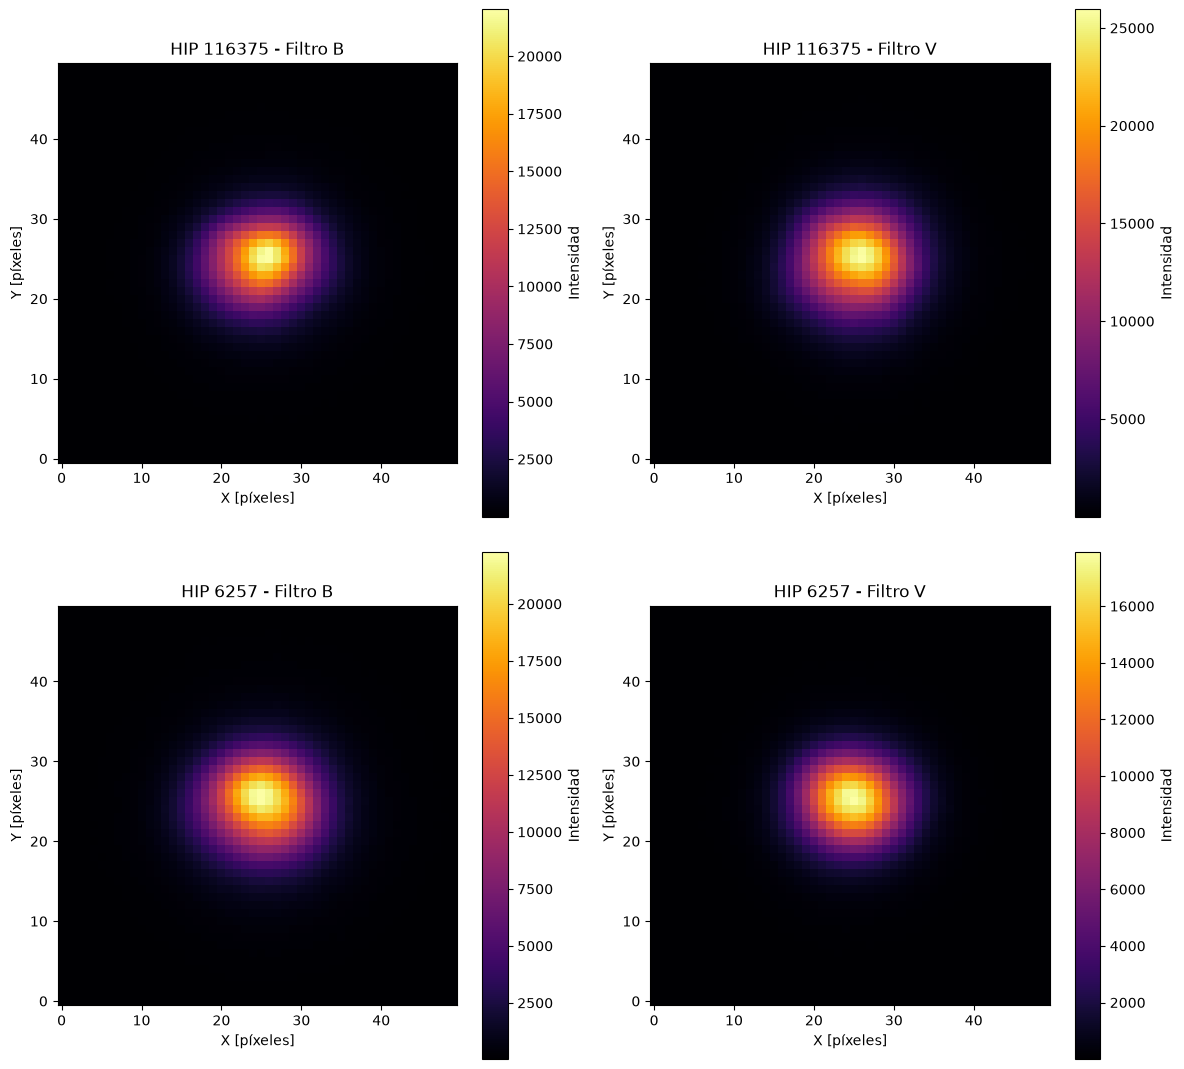

In [36]:
# Tablas e imágenes
tablas = [tabla_2b, tabla_2v, tabla_1b, tabla_1v]
imagenes = [star_2b, star_2v, star_1b, star_1v]

titulos = [
    'HIP 116375 - Filtro B',
    'HIP 116375 - Filtro V',
    'HIP 6257 - Filtro B',
    'HIP 6257 - Filtro V'
]

fig, ax = plt.subplots(2, 2, figsize=(12, 11))

for i in range(4):

    # Coordenadas de la estrella de mayor área
    indice = np.argmax(tablas[i]['area'])

    x = int(round(tablas[i]['xcentroid'][indice]))
    y = int(round(tablas[i]['ycentroid'][indice]))

    # Recorte de 50 x 50 píxeles
    recorte = imagenes[i][y-25:y+25, x-25:x+25]

    # Visualización
    im = ax.flat[i].imshow(recorte, origin='lower', cmap='inferno')
    ax.flat[i].set_title(titulos[i])
    ax.flat[i].set_xlabel('X [píxeles]')
    ax.flat[i].set_ylabel('Y [píxeles]')

    plt.colorbar(im, ax=ax.flat[i], label='Intensidad')

plt.tight_layout()
plt.show()

In [38]:
#Buscamos la fuente que es la estrella (mayor área)
star_1b_index = np.argmax(tabla_1b['area'])
star_1v_index = np.argmax(tabla_1v['area'])

star_2b_index = np.argmax(tabla_2b['area'])
star_2v_index = np.argmax(tabla_2v['area'])

# Dispersión del eje mayor y menor de la elipse ajustada
sigma_major1b = tabla_1b['semimajor_sigma'][star_1b_index].value
sigma_minor1b = tabla_1b['semiminor_sigma'][star_1b_index].value

sigma_major1v = tabla_1v['semimajor_sigma'][star_1v_index].value
sigma_minor1v = tabla_1v['semiminor_sigma'][star_1v_index].value

sigma_major2b = tabla_2b['semimajor_sigma'][star_2b_index].value
sigma_minor2b = tabla_2b['semiminor_sigma'][star_2b_index].value

sigma_major2v = tabla_2v['semimajor_sigma'][star_2v_index].value
sigma_minor2v = tabla_2v['semiminor_sigma'][star_2v_index].value

# FWHM promedio en píxeles, el 2.355 es por formula
fwhm_1b = 2.355 * np.mean([sigma_major1b, sigma_minor1b])
print(f"FWHM HIP 117678 Filtro B = {fwhm_1b} píxeles")

fwhm_1v = 2.355 * np.mean([sigma_major1v, sigma_minor1v])
print(f"FWHM HIP 117678 Filtro V = {fwhm_1v} píxeles")

fwhm_2b = 2.355 * np.mean([sigma_major2b, sigma_minor2b])
print(f"FWHM HIP 116375 Filtro B = {fwhm_2b} píxeles")

fwhm_2v = 2.355 * np.mean([sigma_major2v, sigma_minor2v])
print(f"FWHM HIP 116375 Filtro V = {fwhm_2v} píxeles")

# Conversión a arcosegundos
pixscale = 0.36  # arcsec/pixel (lo obtuve del header) PIXSCALE=0.36

seeing_1b = fwhm_1b * pixscale
seeing_1v = fwhm_1v * pixscale
seeing_2b = fwhm_2b * pixscale
seeing_2v = fwhm_2v * pixscale

print(f"\nSeeing HIP 117678 Filtro B = {seeing_1b} arcsec")
print(f"Seeing HIP 117678 Filtro V = {seeing_1v} arcsec")
print(f"Seeing HIP 116375 Filtro B = {seeing_2b} arcsec")
print(f"Seeing HIP 116375 Filtro V = {seeing_2v} arcsec")

FWHM HIP 117678 Filtro B = 15.593993115758403 píxeles
FWHM HIP 117678 Filtro V = 12.07337118703469 píxeles
FWHM HIP 116375 Filtro B = 13.198943084698557 píxeles
FWHM HIP 116375 Filtro V = 13.542592083564456 píxeles

Seeing HIP 117678 Filtro B = 5.613837521673025 arcsec
Seeing HIP 117678 Filtro V = 4.346413627332488 arcsec
Seeing HIP 116375 Filtro B = 4.751619510491481 arcsec
Seeing HIP 116375 Filtro V = 4.875333150083204 arcsec


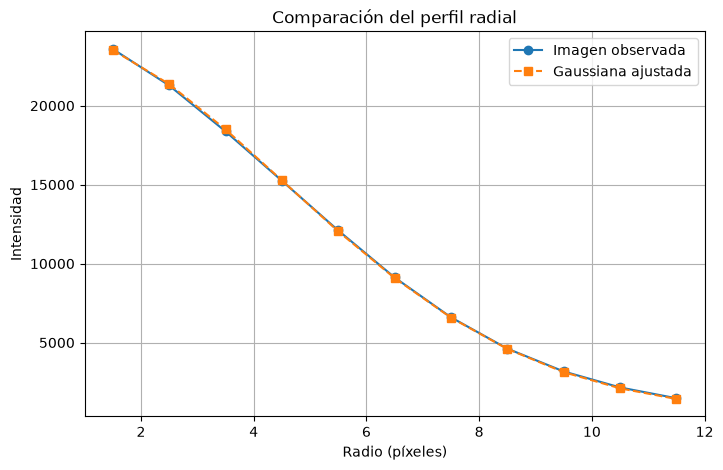

In [47]:
from photutils.profiles import RadialProfile

# Centro de la estrella en el recorte
centro = (radio, radio)

# Radios
radios = np.arange(1, 13, 1)

# Perfil radial observado
perfil_obs = RadialProfile(recorte, centro, radii=radios)

# Modelo gaussiano
imagen_modelo = modelo_ajustado(xx, yy)
perfil_mod = RadialProfile(imagen_modelo, centro, radii=radios)

# Gráfico
plt.figure(figsize=(8, 5))

plt.plot(perfil_obs.radius, perfil_obs.profile, 'o-', label='Imagen observada')
plt.plot(perfil_mod.radius, perfil_mod.profile, 's--', label='Gaussiana ajustada')

plt.xlabel('Radio (píxeles)')
plt.ylabel('Intensidad')
plt.title('Comparación del perfil radial')
plt.legend()
plt.grid()
plt.show()

In [56]:
#Promedio total
valores = [seeing_1b, seeing_1v, seeing_2b, seeing_2v]
seeing_promedio = np.mean(valores)
print(f"Seeing promedio = {seeing_promedio} arcsec")

Seeing promedio = 4.89680095239505 arcsec


Radio 3: FWHM = 7.29 píxeles (2.62")
Radio 6: FWHM = 9.84 píxeles (3.54")
Radio 10: FWHM = 10.46 píxeles (3.76")


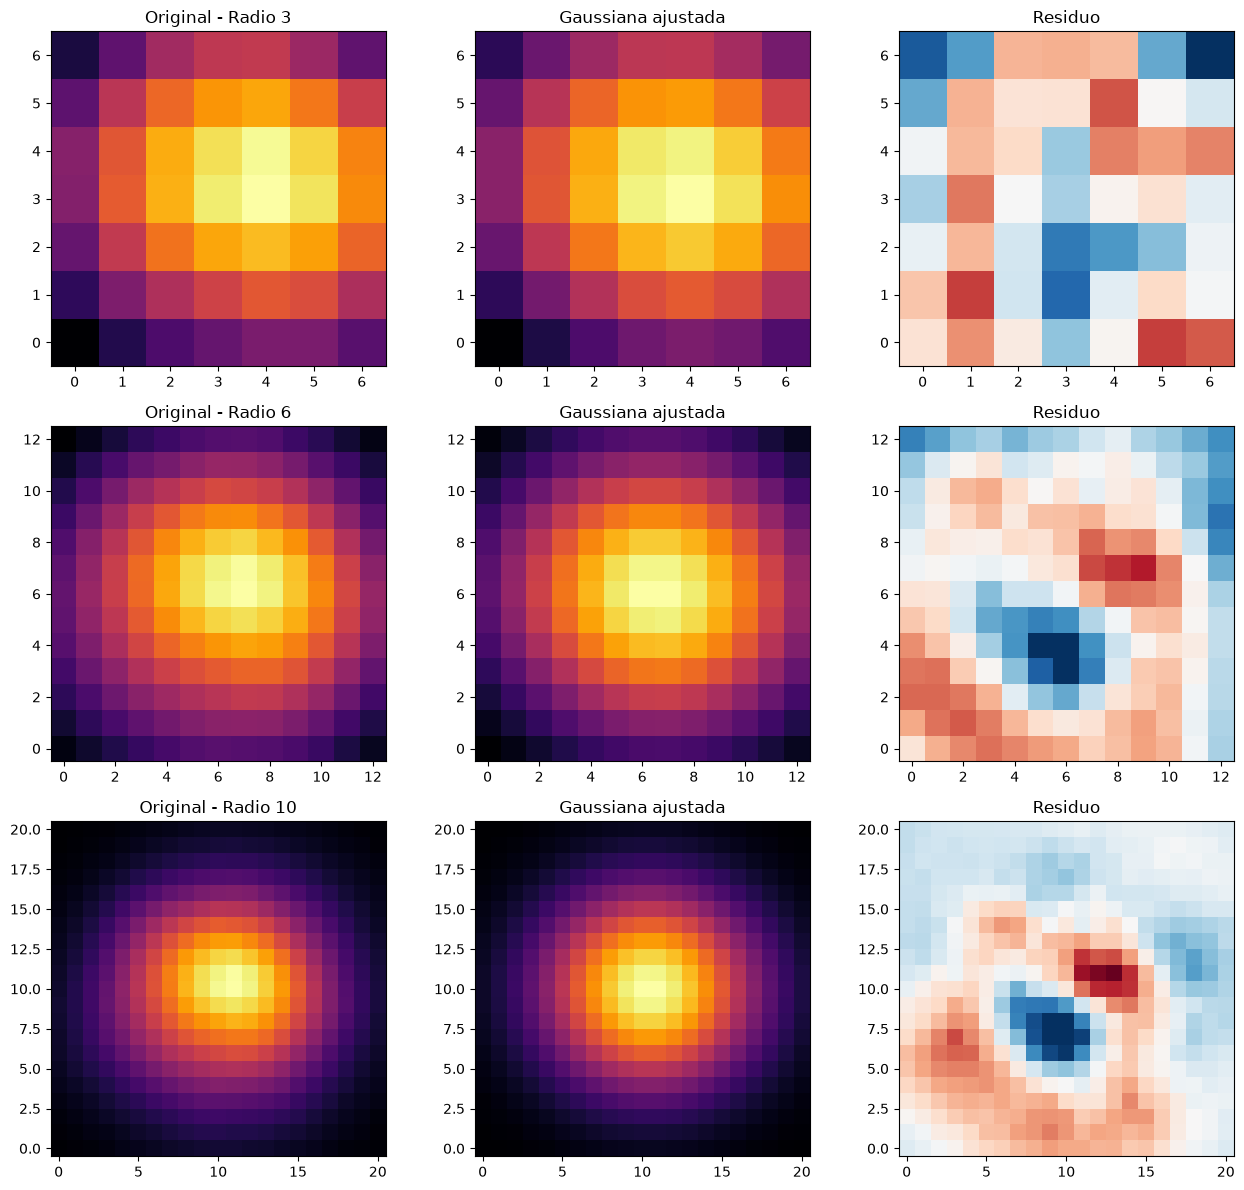

In [57]:
radios_ajuste = [3, 6, 10]

fig, ax = plt.subplots(3, 3, figsize=(13, 12))

for i, radio in enumerate(radios_ajuste):

    recorte = star_2v[y-radio:y+radio+1, x-radio:x+radio+1]

    yy, xx = np.mgrid[:recorte.shape[0], :recorte.shape[1]]

    fondo = np.nanmedian(recorte)
    amplitud = np.nanmax(recorte) - fondo

    modelo = models.Gaussian2D(
        amplitude=amplitud,
        x_mean=radio,
        y_mean=radio,
        x_stddev=3,
        y_stddev=3
    ) + models.Const2D(amplitude=fondo)

    modelo[0].x_stddev.bounds = (0.1, 15)
    modelo[0].y_stddev.bounds = (0.1, 15)

    ajuste = fitting.LevMarLSQFitter()
    resultado = ajuste(modelo, xx, yy, recorte)

    imagen_modelo = resultado(xx, yy)
    residuo = recorte - imagen_modelo

    limite = np.nanpercentile(np.abs(residuo), 99)

    ax[i, 0].imshow(recorte, origin='lower', cmap='inferno')
    ax[i, 0].set_title(f'Original - Radio {radio}')

    ax[i, 1].imshow(imagen_modelo, origin='lower', cmap='inferno')
    ax[i, 1].set_title('Gaussiana ajustada')

    ax[i, 2].imshow(
        residuo,
        origin='lower',
        cmap='RdBu_r',
        vmin=-limite,
        vmax=limite
    )
    ax[i, 2].set_title('Residuo')

    fwhm = 2.355 * np.mean([
        resultado[0].x_stddev.value,
        resultado[0].y_stddev.value
    ])

    print(f'Radio {radio}: FWHM = {fwhm:.2f} píxeles ({fwhm*0.36:.2f}")')

plt.tight_layout()
plt.show()

In [58]:
radios_ajuste = [3, 6, 10]

for radio in radios_ajuste:

    recorte = star_2v[y-radio:y+radio+1, x-radio:x+radio+1]

    yy, xx = np.mgrid[:recorte.shape[0], :recorte.shape[1]]

    fondo = np.nanmedian(recorte)
    amplitud = np.nanmax(recorte) - fondo

    modelo = models.Gaussian2D(
        amplitude=amplitud,
        x_mean=radio,
        y_mean=radio,
        x_stddev=3,
        y_stddev=3
    ) + models.Const2D(amplitude=fondo)

    ajuste = fitting.LevMarLSQFitter()
    resultado = ajuste(modelo, xx, yy, recorte)

    residuo = recorte - resultado(xx, yy)

    print(f'\nRadio {radio}')
    print(f'Residuo medio: {np.nanmean(residuo):.4f}')
    print(f'Desviación del residuo: {np.nanstd(residuo):.4f}')
    print(f'Residuo máximo: {np.nanmax(residuo):.4f}')
    print(f'Residuo mínimo: {np.nanmin(residuo):.4f}')


Radio 3
Residuo medio: -0.0000
Desviación del residuo: 201.1453
Residuo máximo: 325.8798
Residuo mínimo: -538.5549

Radio 6
Residuo medio: -0.0000
Desviación del residuo: 506.6591
Residuo máximo: 1061.9322
Residuo mínimo: -1444.8328

Radio 10
Residuo medio: 0.0000
Desviación del residuo: 475.9475
Residuo máximo: 1484.6509
Residuo mínimo: -1930.2785


In [59]:
radios_ajuste = [3, 6, 10]

for radio in radios_ajuste:

    recorte = star_2v[y-radio:y+radio+1, x-radio:x+radio+1]

    yy, xx = np.mgrid[:recorte.shape[0], :recorte.shape[1]]

    fondo = np.nanmedian(recorte)
    amplitud = np.nanmax(recorte) - fondo

    modelo = models.Gaussian2D(
        amplitude=amplitud,
        x_mean=radio,
        y_mean=radio,
        x_stddev=3,
        y_stddev=3
    ) + models.Const2D(amplitude=fondo)

    ajuste = fitting.LevMarLSQFitter()
    resultado = ajuste(modelo, xx, yy, recorte)

    residuo = recorte - resultado(xx, yy)

    rmse = np.sqrt(np.nanmean(residuo**2))
    error_relativo = (rmse / amplitud) * 100

    print(f'Radio {radio}')
    print(f'RMSE: {rmse:.2f}')
    print(f'Error relativo: {error_relativo:.2f} %')
    print('-' * 30)

Radio 3
RMSE: 201.15
Error relativo: 3.79 %
------------------------------
Radio 6
RMSE: 506.66
Error relativo: 3.86 %
------------------------------
Radio 10
RMSE: 475.95
Error relativo: 2.25 %
------------------------------


In [60]:
from photutils.profiles import RadialProfile
import numpy as np
import matplotlib.pyplot as plt

# Centro de la estrella
centro = (x, y)

# Perfil radial
radios = np.arange(1, 21, 1)

perfil = RadialProfile(star_2v, centro, radii=radios)

# Intensidad máxima y fondo
fondo = np.nanmedian(perfil.profile[-5:])
maximo = np.nanmax(perfil.profile)

# Mitad de intensidad
mitad = fondo + (maximo - fondo) / 2

# Encontramos el primer radio que cruza la mitad
indices = np.where(perfil.profile <= mitad)[0]

if len(indices) > 0:
    i = indices[0]

    # Interpolación lineal
    r1, r2 = perfil.radius[i-1], perfil.radius[i]
    I1, I2 = perfil.profile[i-1], perfil.profile[i]

    radio_mitad = r1 + (mitad - I1) * (r2 - r1) / (I2 - I1)

    # FWHM
    fwhm = 2 * radio_mitad
    fwhm_arcsec = fwhm * 0.36

    print(f'Radio a media altura: {radio_mitad:.2f} píxeles')
    print(f'FWHM radial: {fwhm:.2f} píxeles')
    print(f'FWHM radial: {fwhm_arcsec:.2f} arcsec')

else:
    print('No se encontró el cruce de la mitad de intensidad.')

Radio a media altura: 5.57 píxeles
FWHM radial: 11.14 píxeles
FWHM radial: 4.01 arcsec


In [61]:
print("Píxeles NaN:", np.isnan(recorte).sum())
print("Píxeles infinitos:", np.isinf(recorte).sum())
print("Total de píxeles:", recorte.size)

Píxeles NaN: 0
Píxeles infinitos: 0
Total de píxeles: 441


In [62]:
print("NaN en imagen:", np.isnan(star_2v).sum())
print("Infinitos en imagen:", np.isinf(star_2v).sum())

NaN en imagen: 3
Infinitos en imagen: 0


NaN en imagen: 3
Infinitos en imagen: 0


Radio a media altura: 5.58 píxeles
FWHM radial: 11.15 píxeles
FWHM radial: 4.02 arcsec


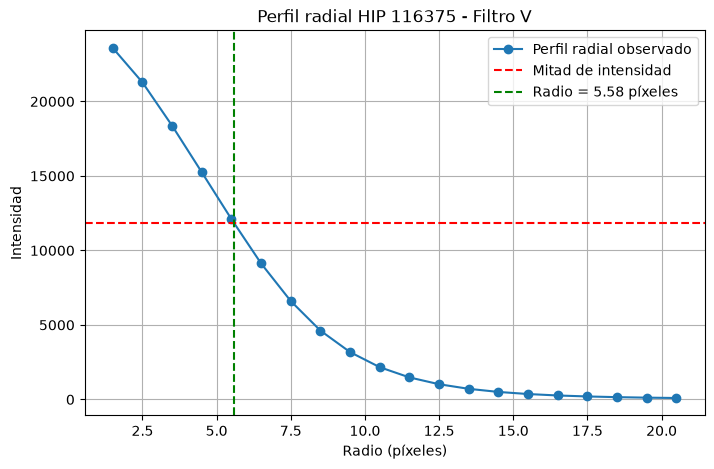

In [63]:
from photutils.profiles import RadialProfile
import numpy as np
import matplotlib.pyplot as plt

# Centro de la estrella
centro = (x, y)

# Revisamos valores no finitos en la imagen
print("NaN en imagen:", np.isnan(star_2v).sum())
print("Infinitos en imagen:", np.isinf(star_2v).sum())

# Construimos el perfil radial
radios = np.arange(1, 22, 1)

perfil = RadialProfile(
    star_2v,
    centro,
    radii=radios
)

# Fondo e intensidad máxima del perfil
fondo = np.nanmedian(perfil.profile[-5:])
maximo = np.nanmax(perfil.profile)

# Intensidad a mitad de altura
mitad = fondo + (maximo - fondo) / 2

# Buscamos el primer cruce de la mitad de intensidad
indices = np.where(perfil.profile <= mitad)[0]

if len(indices) > 0:

    i = indices[0]

    if i > 0:
        r1, r2 = perfil.radius[i-1], perfil.radius[i]
        I1, I2 = perfil.profile[i-1], perfil.profile[i]

        # Interpolación lineal
        radio_mitad = r1 + (mitad - I1) * (r2 - r1) / (I2 - I1)

        # Calculamos FWHM
        fwhm = 2 * radio_mitad
        escala = 0.36  # arcsec/píxel
        fwhm_arcsec = fwhm * escala

        print(f"Radio a media altura: {radio_mitad:.2f} píxeles")
        print(f"FWHM radial: {fwhm:.2f} píxeles")
        print(f"FWHM radial: {fwhm_arcsec:.2f} arcsec")

    else:
        print("El perfil comienza por debajo de la mitad de intensidad.")

else:
    print("No se encontró el cruce de la mitad de intensidad.")

# Gráfico del perfil radial
plt.figure(figsize=(8, 5))

plt.plot(
    perfil.radius,
    perfil.profile,
    'o-',
    label='Perfil radial observado'
)

plt.axhline(
    mitad,
    color='red',
    linestyle='--',
    label='Mitad de intensidad'
)

if len(indices) > 0 and i > 0:
    plt.axvline(
        radio_mitad,
        color='green',
        linestyle='--',
        label=f'Radio = {radio_mitad:.2f} píxeles'
    )

plt.xlabel('Radio (píxeles)')
plt.ylabel('Intensidad')
plt.title('Perfil radial HIP 116375 - Filtro V')
plt.legend()
plt.grid()
plt.show()

In [64]:
# FWHM obtenido del ajuste gaussiano 2D
fwhm_pixeles = 10.46

# Escala de placa
escala = 0.36  # arcsec/píxel

# Seeing observado
seeing_observado = fwhm_pixeles * escala

print(f"FWHM: {fwhm_pixeles:.2f} píxeles")
print(f"Seeing observado: {seeing_observado:.2f} arcsec")

FWHM: 10.46 píxeles
Seeing observado: 3.77 arcsec
